# Delivery Duration Prediction

## 1. Data preparation

- Load the dataset with pandas
- Inspect columns, data types, and unique values
- Clean strings, parse dates/times, and filter out invalid coordinates/distances

In [47]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [48]:
df = pd.read_csv('data/raw/train.csv')
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [49]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['id', 'delivery_person_id', 'delivery_person_age',
       'delivery_person_ratings', 'restaurant_latitude',
       'restaurant_longitude', 'delivery_location_latitude',
       'delivery_location_longitude', 'order_date', 'time_orderd',
       'time_order_picked', 'weatherconditions', 'road_traffic_density',
       'vehicle_condition', 'type_of_order', 'type_of_vehicle',
       'multiple_deliveries', 'festival', 'city', 'time_taken(min)'],
      dtype='object')

In [50]:
for col in df.columns:
	print(col)
	print(df[col].unique()[:5])
	print(df[col].nunique())
	print()

id
['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ']
45593

delivery_person_id
['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ']
1320

delivery_person_age
['37' '34' '23' '38' '32']
23

delivery_person_ratings
['4.9' '4.5' '4.4' '4.7' '4.6']
29

restaurant_latitude
[22.745049 12.913041 12.914264 11.003669 12.972793]
657

restaurant_longitude
[75.892471 77.683237 77.6784   76.976494 80.249982]
518

delivery_location_latitude
[22.765049 13.043041 12.924264 11.053669 13.012793]
4373

delivery_location_longitude
[75.912471 77.813237 77.6884   77.026494 80.289982]
4373

order_date
['19-03-2022' '25-03-2022' '05-04-2022' '26-03-2022' '11-03-2022']
44

time_orderd
['11:30:00' '19:45:00' '08:30:00' '18:00:00' '13:30:00']
177

time_order_picked
['11:45:00' '19:50:00' '08:45:00' '18:10:00' '13:45:00']
193

weatherconditions
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Cloudy' 'conditions Fog']
7

road_traffic_density
[

In [51]:
df.dtypes

id                              object
delivery_person_id              object
delivery_person_age             object
delivery_person_ratings         object
restaurant_latitude            float64
restaurant_longitude           float64
delivery_location_latitude     float64
delivery_location_longitude    float64
order_date                      object
time_orderd                     object
time_order_picked               object
weatherconditions               object
road_traffic_density            object
vehicle_condition                int64
type_of_order                   object
type_of_vehicle                 object
multiple_deliveries             object
festival                        object
city                            object
time_taken(min)                 object
dtype: object

In [52]:
df['id'] = df['id'].astype(str).str.strip()
df = df.drop_duplicates()

df['time_taken(min)'] = df['time_taken(min)'].str.replace('(min)', '')
df['duration'] = pd.to_numeric(df['time_taken(min)'], errors='coerce')

categorical_map = {'weatherconditions': 'weather', 'road_traffic_density': 'traffic',
                   'type_of_vehicle': 'vehicle', 'type_of_order': 'order_type'}

for src, dest in categorical_map.items():
	df[dest] = (df[src].astype(str).str.strip().str.lower().str.removeprefix('conditions').str.strip().str.replace(' ', '_'))
	df[dest] = df[dest].replace({'': 'unknown', 'nan': 'unknown', 'none': 'unknown'})

df[['id', 'weather', 'traffic', 'vehicle', 'order_type', 'duration']].head()

,id,weather,traffic,vehicle,order_type,duration
0,0x4607,sunny,high,motorcycle,snack,24
1,0xb379,stormy,jam,scooter,snack,33
2,0x5d6d,sandstorms,low,motorcycle,drinks,26
3,0x7a6a,sunny,medium,motorcycle,buffet,21
4,0x70a2,cloudy,high,scooter,snack,30


In [53]:
for col in ["weather", "traffic", "vehicle", "order_type"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))
    print("Unknown percentage:",
          f"{df[col].eq('unknown').mean() * 100:.2f}%")


weather
weather
fog           7654
stormy        7586
cloudy        7536
sandstorms    7495
windy         7422
sunny         7284
unknown        616
Name: count, dtype: int64
Unknown percentage: 1.35%

traffic
traffic
low        15477
jam        14143
medium     10947
high        4425
unknown      601
Name: count, dtype: int64
Unknown percentage: 1.32%

vehicle
vehicle
motorcycle          26435
scooter             15276
electric_scooter     3814
bicycle                68
Name: count, dtype: int64
Unknown percentage: 0.00%

order_type
order_type
snack     11533
meal      11458
drinks    11322
buffet    11280
Name: count, dtype: int64
Unknown percentage: 0.00%


In [54]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%d-%m-%Y', errors='coerce')
times = pd.to_datetime(df['time_orderd'].astype(str).str.strip(), format='%H:%M:%S', errors='coerce')

df['order_hour'] = times.dt.hour.fillna(-1).astype(int)
df['hour_missing'] = (df['order_hour'] == -1).astype(int)

df[['order_date', 'order_hour', 'hour_missing']].head()

,order_date,order_hour,hour_missing
0,2022-03-19,11,0
1,2022-03-25,19,0
2,2022-03-19,8,0
3,2022-04-05,18,0
4,2022-03-26,13,0


In [55]:
import math

def haversine_km(lat1, lon1, lat2, lon2):
	d_lat = math.radians(lat2 - lat1)
	d_lon = math.radians(lon2 - lon1)

	lat1 = math.radians(lat1)
	lat2 = math.radians(lat2)

	a = (math.sin(d_lat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(d_lon / 2) ** 2)

	earth_radius = 6371.0088

	c = 2 * math.asin(math.sqrt(min(1.0, max(0.0, a))))

	return earth_radius * c

df['distance_km'] = [
	haversine_km(r_lat, r_lon, d_lat, d_lon)
  for r_lat, r_lon, d_lat, d_lon in zip(df['restaurant_latitude'], df['restaurant_longitude'],
    df['delivery_location_latitude'], df['delivery_location_longitude'])
]

df[['distance_km', 'duration']].head

<bound method NDFrame.head of        distance_km  duration
0         3.025153        24
1        20.183558        33
2         1.552760        26
3         7.790412        21
4         6.210147        30
...            ...       ...
45588     1.489848        32
45589    11.007750        36
45590     4.657202        16
45591     6.232402        26
45592    12.074412        36

[45593 rows x 2 columns]>

In [56]:
import json
from urllib.request import Request, urlopen

url = "https://nominatim.openstreetmap.org/search?country=India&format=json"
req = Request(url, headers={"User-Agent": "delivery-eta-project/1.0"})

with urlopen(req, timeout=10) as response:
    bbox = json.loads(response.read().decode())[0]["boundingbox"]
    
    print("OpenStreetMap India Bounding Box:")
    print(f"  Latitude : {float(bbox[0]):.2f} to {float(bbox[1]):.2f}  --> Project rule: [6, 36]")
    print(f"  Longitude: {float(bbox[2]):.2f} to {float(bbox[3]):.2f} --> Project rule: [67, 98]\n")

print("Raw CSV coordinate ranges (before cleaning):")
display(df[['restaurant_latitude', 'restaurant_longitude', 
            'delivery_location_latitude', 'delivery_location_longitude']].describe().loc[['min', 'max']])

OpenStreetMap India Bounding Box:
  Latitude : 6.55 to 35.67  --> Project rule: [6, 36]
  Longitude: 67.92 to 97.40 --> Project rule: [67, 98]

Raw CSV coordinate ranges (before cleaning):


,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude
min,-30.905562,-88.366217,0.010000,0.010000
max,30.914057,88.433452,31.054057,88.563452


In [57]:
df.loc[(df['restaurant_latitude'] < 0) | (df['restaurant_longitude'] < 0),
  ['restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude']
].head(10)

,restaurant_latitude,restaurant_longitude,delivery_location_latitude,delivery_location_longitude
92,-27.163303,78.057044,27.233303,78.127044
283,-27.165108,78.015053,27.225108,78.075053
289,-18.551440,-73.804855,18.611440,73.864855
425,-30.366322,-78.070453,30.496322,78.200453
534,-12.325461,-76.632278,12.385461,76.692278
583,-12.316967,76.603067,12.326967,76.613067
762,-23.359194,-85.325447,23.449194,85.415447
1059,-26.477750,-80.351569,26.487750,80.361569
1091,-15.546594,73.760431,15.606594,73.820431
1157,-12.337978,76.616792,12.387978,76.666792


In [58]:
df['restaurant_latitude'].abs().describe()
df['restaurant_longitude'].abs().describe()

count    45593.000000
mean        70.782088
std         21.118611
min          0.000000
25%         73.170283
50%         75.898497
75%         78.046106
max         88.433452
Name: restaurant_longitude, dtype: float64

In [59]:
df['restaurant_latitude'] = df['restaurant_latitude'].abs()
df['restaurant_longitude'] = df['restaurant_longitude'].abs()

In [60]:
valid_coords = (
    df['restaurant_latitude'].between(6, 36) & df['restaurant_longitude'].between(67, 98) &
    df['delivery_location_latitude'].between(6, 36) & df['delivery_location_longitude'].between(67, 98)
)
valid_distance = (df['distance_km'] > 0) & (df['distance_km'] <= 100)
valid_target = df['duration'].notna() & (df['duration'] > 0)
valid_date = df['order_date'].notna()

df = df[valid_coords & valid_distance & valid_target & valid_date].copy()
df = df.sort_values(['order_date', 'id']).reset_index(drop=True)

print("Clean rows:", len(df))

Clean rows: 41522


In [61]:
df['weekend'] = (df['order_date'].dt.weekday >= 5).astype(int)
df['lunch'] = ((df['order_hour'] >= 11) & (df['order_hour'] < 14)).astype(int)
df['dinner'] = ((df['order_hour'] >= 17) & (df['order_hour'] < 21)).astype(int)

numerical = ['distance_km', 'order_hour', 'hour_missing', 'weekend', 'lunch', 'dinner']
categorical = ['weather', 'traffic', 'vehicle', 'order_type']

df[numerical + categorical + ['duration']].head()

,distance_km,order_hour,hour_missing,weekend,lunch,dinner,weather,traffic,vehicle,order_type,duration
0,1.468903,-1,1,0,0,0,unknown,unknown,scooter,drinks,19
1,2.984672,-1,1,0,0,0,unknown,unknown,electric_scooter,snack,31
2,3.026936,-1,1,0,0,0,unknown,unknown,motorcycle,meal,21
3,3.121293,-1,1,0,0,0,unknown,unknown,scooter,snack,30
4,6.176340,-1,1,0,0,0,fog,high,scooter,buffet,24


## 2. Setting up the validation framework
- Split 60% / 20% / 20% chronologically by unique `order_date`

In [62]:
days = np.sort(df['order_date'].unique())
n_days = len(days)

first = int(n_days * 0.6)
second = int(n_days * 0.8)

df_train = df[df['order_date'] < days[first]].copy()
df_val = df[(df['order_date'] >= days[first]) & (df['order_date'] < days[second])].copy()
df_test = df[df['order_date'] >= days[second]].copy()

df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

len(df_train), len(df_val), len(df_test)


(23724, 9002, 8796)

In [63]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.duration.values
y_val = df_val.duration.values
y_test = df_test.duration.values
y_full_train = df_full_train.duration.values

## 3. Exploratory Data Analysis (EDA)
Explore training dates (`df_train`) only:
- Summary statistics of numerical and categorical features
- Target variable (`duration`) distribution: why raw minutes work well without a `log1p` transform
- Distance vs. duration relationship
- Feature importance: categorical group differences (like risk ratio in Chapter 3), mutual information, and numerical correlations

In [64]:
df_train[numerical + categorical].describe(include='all').T

for col in categorical:
	print(col)
	print(df_train[col].value_counts(dropna=False))
	print()

weather
weather
fog           3969
stormy        3951
cloudy        3938
sandstorms    3907
windy         3870
sunny         3854
unknown        235
Name: count, dtype: int64

traffic
traffic
low        8057
jam        7420
medium     5790
high       2234
unknown     223
Name: count, dtype: int64

vehicle
vehicle
motorcycle          13807
scooter              7933
electric_scooter     1957
bicycle                27
Name: count, dtype: int64

order_type
order_type
snack     6042
buffet    5937
meal      5928
drinks    5817
Name: count, dtype: int64



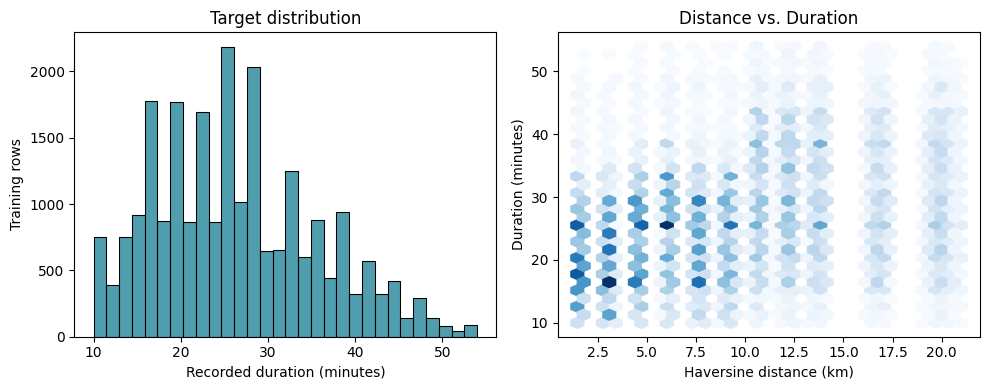

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(y_train, bins=30, color='#147d92', ax=axes[0])
axes[0].set(xlabel='Recorded duration (minutes)', ylabel='Training rows', title='Target distribution')
axes[1].hexbin(df_train.distance_km, y_train, gridsize=30, mincnt=1, cmap='Blues')
axes[1].set(xlabel='Haversine distance (km)', ylabel='Duration (minutes)', title='Distance vs. Duration')

plt.tight_layout()
plt.show()

In [66]:
for c in categorical:
    print(c)
    display(df_train.groupby(c).duration.agg(['count', 'mean', 'median']).sort_values('mean'))

weather


,count,mean,median
weather,,,
sunny,3854,22.037364,21.0
stormy,3951,25.888636,26.0
sandstorms,3907,25.964167,26.0
windy,3870,26.006202,26.0
unknown,235,26.463830,26.0
cloudy,3938,29.118334,29.0
fog,3969,29.167045,29.0


traffic


,count,mean,median
traffic,,,
low,8057,21.415788,21.0
unknown,223,26.390135,26.0
medium,5790,26.825561,27.0
high,2234,27.397941,27.0
jam,7420,31.131536,31.0


vehicle


,count,mean,median
vehicle,,,
electric_scooter,1957,24.595810,24.0
scooter,7933,24.619816,24.0
bicycle,27,26.925926,26.0
motorcycle,13807,27.651554,27.0


order_type


,count,mean,median
order_type,,,
buffet,5937,26.286340,26.0
snack,6042,26.346739,26.0
drinks,5817,26.380780,26.0
meal,5928,26.526484,26.0


In [67]:
from sklearn.metrics import mutual_info_score

print("Numerical correlation with duration:")
display(df_train[numerical + ['duration']].corr()['duration'].sort_values(ascending=False))

print("Mutual information score (categorical variables):")
def mutual_info_duration_score(series):
	return mutual_info_score(series, df_train.duration.astype(int))

mi = df_train[categorical].apply(mutual_info_duration_score)
display(mi.sort_values(ascending=False))

Numerical correlation with duration:


duration        1.000000
distance_km     0.322070
dinner          0.247786
order_hour      0.148558
lunch           0.015739
hour_missing    0.003413
weekend        -0.006023
Name: duration, dtype: float64

Mutual information score (categorical variables):


traffic       0.119774
weather       0.059312
vehicle       0.022440
order_type    0.003130
dtype: float64

## 4. Model training and tuning
* Convert DataFrames to lists of dictionaries and encode with `DictVectorizer`
* Define regression evaluation metrics (`mae` and `rmse`)
* Evaluate a simple median baseline model

In [68]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_absolute_error, mean_squared_error

train_dicts = df_train[numerical + categorical].to_dict(orient='records')
val_dicts = df_val[numerical + categorical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

X_train.shape, X_val.shape

((23724, 26), (9002, 26))

In [69]:
dv.get_feature_names_out()

array(['dinner', 'distance_km', 'hour_missing', 'lunch', 'order_hour',
       'order_type=buffet', 'order_type=drinks', 'order_type=meal',
       'order_type=snack', 'traffic=high', 'traffic=jam', 'traffic=low',
       'traffic=medium', 'traffic=unknown', 'vehicle=bicycle',
       'vehicle=electric_scooter', 'vehicle=motorcycle',
       'vehicle=scooter', 'weather=cloudy', 'weather=fog',
       'weather=sandstorms', 'weather=stormy', 'weather=sunny',
       'weather=unknown', 'weather=windy', 'weekend'], dtype=object)

In [70]:
def rmse(y, y_pred):
	se = (y - y_pred) ** 2
	mse = se.mean()
	return np.sqrt(mse)

def mae(y, y_pred):
	return mean_absolute_error(y, y_pred)

y_pred_baseline = np.repeat(np.median(y_train), len(y_val))

print('Baseline Validation MAE:', round(mae(y_val, y_pred_baseline), 3))
print('Baseline Validation RMSE:', round(rmse(y_val, y_pred_baseline), 3))	

Baseline Validation MAE: 7.503
Baseline Validation RMSE: 9.303


In [71]:
# 4.2 Ridge Regression

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

for alpha in [0.1, 10.0, 100.0]:
	model = Ridge(alpha=alpha)
	model.fit(X_train_scaled, y_train)

	y_pred = np.maximum(0.0, model.predict(X_val_scaled))
	print(f"alpha={alpha:<5} -> MAE: {mae(y_val, y_pred):.3f}, RMSE: {rmse(y_val, y_pred):.3f}")

alpha=0.1   -> MAE: 6.160, RMSE: 7.652
alpha=10.0  -> MAE: 6.160, RMSE: 7.652
alpha=100.0 -> MAE: 6.161, RMSE: 7.652


In [72]:
# 4.3 Decision Trees

from sklearn.tree import DecisionTreeRegressor

depths = [1, 2, 4, 6, 8, 10, 15, 20, None]

for depth in depths:
	dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=42)
	dt.fit(X_train, y_train)

	y_pred_train = np.maximum(0.0, dt.predict(X_train))
	y_pred_val = np.maximum(0.0, dt.predict(X_val))

	print(f"max_depth={str(depth):<4} -> train MAE: {mae(y_train, y_pred_train):.3f} | MAE: {mae(y_val, y_pred_val):.3f}")


max_depth=1    -> train MAE: 6.921 | MAE: 6.800
max_depth=2    -> train MAE: 6.541 | MAE: 6.408
max_depth=4    -> train MAE: 5.905 | MAE: 5.911
max_depth=6    -> train MAE: 5.214 | MAE: 5.261
max_depth=8    -> train MAE: 5.099 | MAE: 5.231
max_depth=10   -> train MAE: 5.018 | MAE: 5.287
max_depth=15   -> train MAE: 4.900 | MAE: 5.386
max_depth=20   -> train MAE: 4.854 | MAE: 5.420
max_depth=None -> train MAE: 4.848 | MAE: 5.424


In [81]:
scores = []

for depth in [6, 8]:
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=s, random_state=42)
        dt.fit(X_train, y_train)

        y_pred = np.maximum(0.0, dt.predict(X_val))
        val_mae = mean_absolute_error(y_val, y_pred)
        
        scores.append((depth, s, val_mae))

columns = ['max_depth', 'min_samples_leaf', 'mae']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['mae'])
df_scores_pivot.round(3)


mae       
max_depth             6      8
min_samples_leaf              
1                 5.258  5.245
5                 5.258  5.243
10                5.260  5.233
15                5.262  5.233
20                5.261  5.231
50                5.258  5.213
100               5.255  5.211
200               5.277  5.247

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

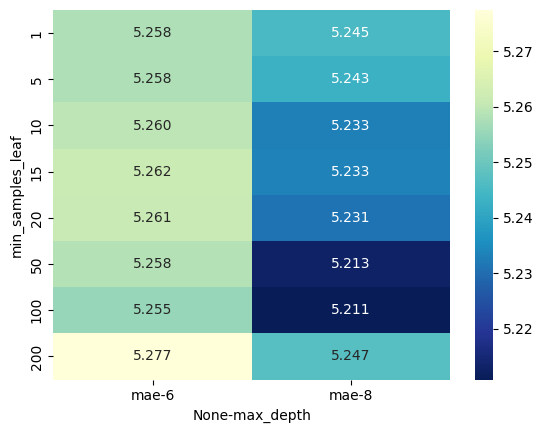

In [82]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f", cmap="YlGnBu_r")

In [83]:
from sklearn.tree import export_text

dt_final = DecisionTreeRegressor(max_depth=8, min_samples_leaf=100, random_state=42)
dt_final.fit(X_train, y_train)

print(export_text(dt_final, feature_names=list(dv.get_feature_names_out())))

|--- traffic=low <= 0.50
|   |--- distance_km <= 9.81
|   |   |--- traffic=medium <= 0.50
|   |   |   |--- vehicle=motorcycle <= 0.50
|   |   |   |   |--- weather=sunny <= 0.50
|   |   |   |   |   |--- weather=fog <= 0.50
|   |   |   |   |   |   |--- weather=cloudy <= 0.50
|   |   |   |   |   |   |   |--- distance_km <= 9.05
|   |   |   |   |   |   |   |   |--- value: [24.57]
|   |   |   |   |   |   |   |--- distance_km >  9.05
|   |   |   |   |   |   |   |   |--- value: [23.37]
|   |   |   |   |   |   |--- weather=cloudy >  0.50
|   |   |   |   |   |   |   |--- distance_km <= 6.22
|   |   |   |   |   |   |   |   |--- value: [29.22]
|   |   |   |   |   |   |   |--- distance_km >  6.22
|   |   |   |   |   |   |   |   |--- value: [29.76]
|   |   |   |   |   |--- weather=fog >  0.50
|   |   |   |   |   |   |--- dinner <= 0.50
|   |   |   |   |   |   |   |--- distance_km <= 5.91
|   |   |   |   |   |   |   |   |--- value: [28.54]
|   |   |   |   |   |   |   |--- distance_km >  5.91
|   |  

Text(0, 0.5, 'Validation MAE')

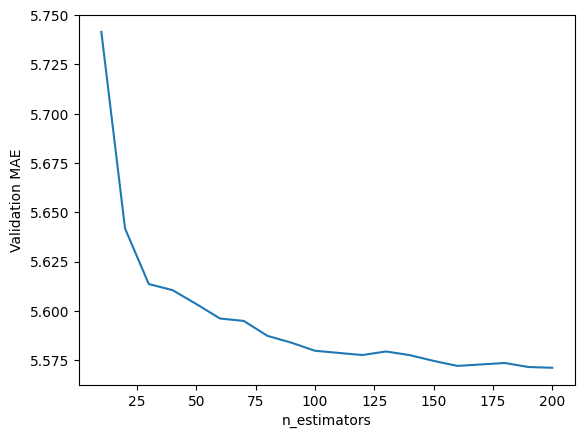

In [85]:
# 4.4 Random Forest
from sklearn.ensemble import RandomForestRegressor

scores = []

for n in range(10, 201, 10):
	rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
	rf.fit(X_train, y_train)

	y_pred = np.maximum(0.0, rf.predict(X_val))
	scores.append((n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['n_estimators', 'mae'])
plt.plot(df_scores.n_estimators, df_scores.mae)
plt.xlabel('n_estimators')
plt.ylabel('Validation MAE')


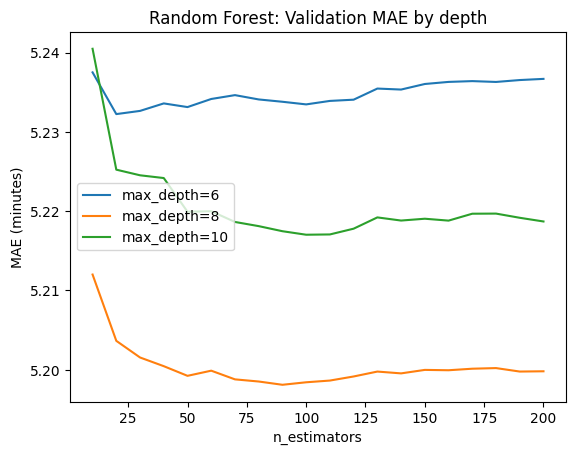

In [107]:
scores = []

for d in [6, 8, 10]:
	for n in range(10, 201, 10):
		rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
		rf.fit(X_train, y_train)
		y_pred = np.maximum(0.0, rf.predict(X_val))
		scores.append((d, n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'mae'])

for d in [6, 8, 10]:
	df_subset = df_scores[df_scores.max_depth == d]
	plt.plot(df_subset.n_estimators, df_subset.mae, label='max_depth=%d' % d)

plt.xlabel('n_estimators')
plt.ylabel('MAE (minutes)')
plt.title('Random Forest: Validation MAE by depth')
plt.legend()
plt.show()

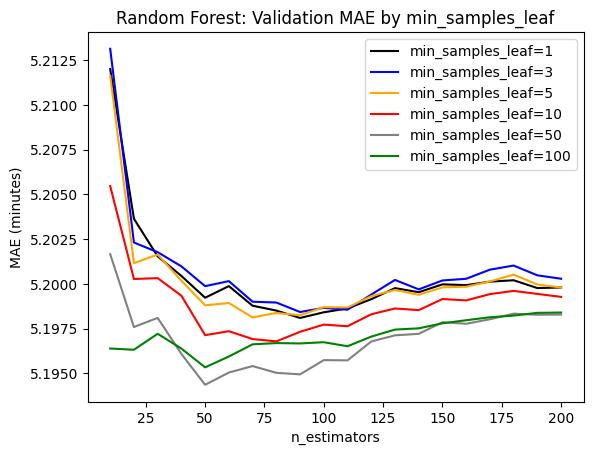

In [108]:
max_depth = 8

scores = []

for s in [1, 3, 5, 10, 50, 100]:
	for n in range(10, 201, 10):
		rf = RandomForestRegressor(n_estimators=n, max_depth=max_depth, min_samples_leaf=s,
		                           random_state=1, n_jobs=-1)
		rf.fit(X_train, y_train)

		y_pred = np.maximum(0.0, rf.predict(X_val))
		scores.append((s, n, mae(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'mae'])

colors = ['black', 'blue', 'orange', 'red', 'grey', 'green']
values = [1, 3, 5, 10, 50, 100]

for s, col in zip(values, colors):
	df_subset = df_scores[df_scores.min_samples_leaf == s]
	plt.plot(df_subset.n_estimators, df_subset.mae, color=col, label='min_samples_leaf=%d' % s)

plt.xlabel('n_estimators')
plt.ylabel('MAE (minutes)')
plt.title('Random Forest: Validation MAE by min_samples_leaf')
plt.legend()
plt.show()

In [90]:
min_samples_leaf = 50

rf = RandomForestRegressor(n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                           random_state=1, n_jobs=-1)

rf.fit(X_train, y_train)

y_pred = np.maximum(0.0, rf.predict(X_val))
print('Random Forest MAE:', mae(y_val, y_pred), ' RMSE:', rmse(y_val, y_pred))

Random Forest MAE: 5.195737497281363  RMSE: 6.610621141955094


In [91]:
# 4.5 XGBoost

import xgboost as xgb

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

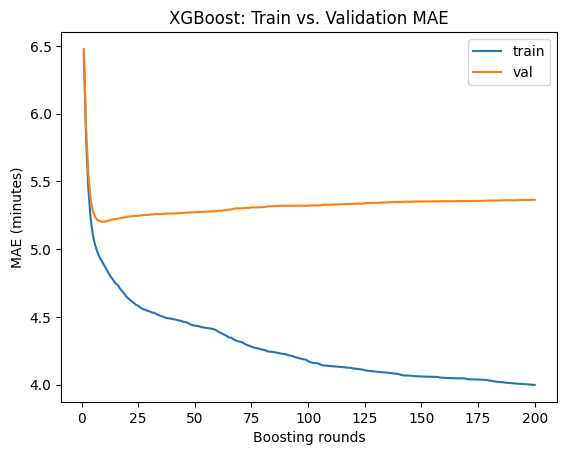

In [95]:
def train_xgb(params, num_boost_round=200):
  evals_result = {}
  model = xgb.train(params, dtrain, num_boost_round=num_boost_round, evals=watchlist,
                    evals_result=evals_result, verbose_eval=0)
  train_maes = evals_result['train']['mae']
  val_maes = evals_result['val']['mae']
  df = pd.DataFrame({
    'iter': range(1, len(train_maes) + 1),
    'train_mae': train_maes,
    'val_mae': val_maes,
  })
  return model, df

base_params = {
    'eta': 0.3,
    'max_depth': 8,
    'min_child_weight': 1,

    'objective': 'reg:absoluteerror',
    'eval_metric': 'mae',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

scores = {}
model, df = train_xgb(base_params)

plt.plot(df.iter, df.train_mae, label='train')
plt.plot(df.iter, df.val_mae, label='val')
plt.xlabel('Boosting rounds')
plt.ylabel('MAE (minutes)')
plt.title('XGBoost: Train vs. Validation MAE')
plt.legend()
plt.show()

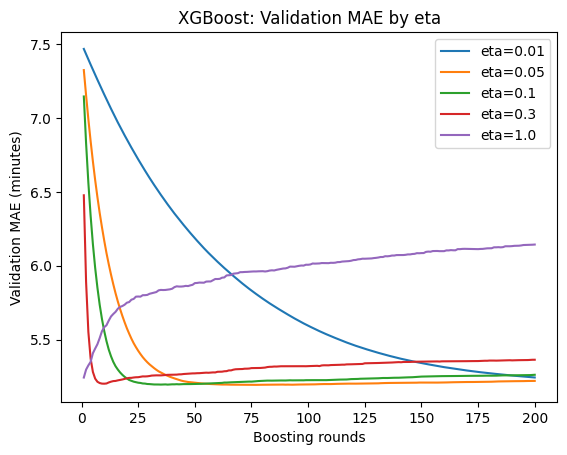

In [ ]:
scores = {}

for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    params = {**base_params, 'eta': eta}
    _, df = train_xgb(params)
    scores[f'eta={eta}'] = df

for key, df in scores.items():
    plt.plot(df.iter, df.val_mae, label=key)

plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by eta')
plt.legend()
plt.show()

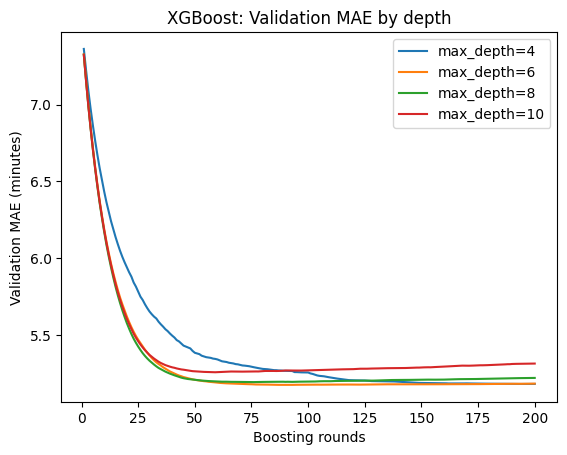

In [99]:
best_eta = 0.05

scores = {}

for d in [4, 6, 8, 10]:
    params = {**base_params, 'eta': best_eta, 'max_depth': d}
    _, df = train_xgb(params)
    scores[f'max_depth={d}'] = df

for key, df in scores.items():
    plt.plot(df.iter, df.val_mae, label=key)

plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by depth')
plt.legend()
plt.show()

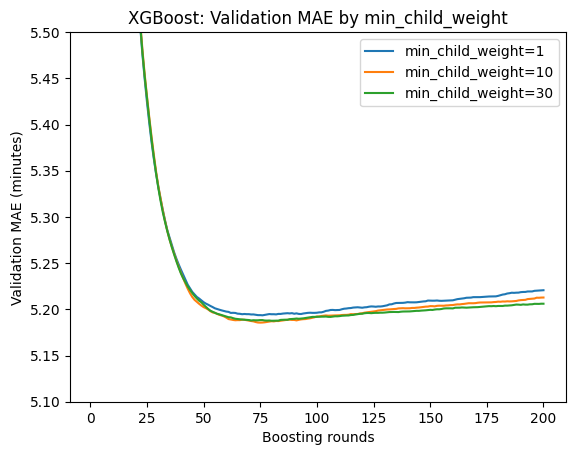

In [104]:
best_depth = 8
scores = {}

for mcw in [1, 10, 30]:
    params = {**base_params, 'eta': best_eta, 'max_depth': best_depth,
              'min_child_weight': mcw}
    _, df = train_xgb(params)
    scores[f'min_child_weight={mcw}'] = df

for key, df in scores.items():
    plt.plot(df.iter, df.val_mae, label=key)

plt.ylim(5.1, 5.5)
plt.xlabel('Boosting rounds')
plt.ylabel('Validation MAE (minutes)')
plt.title(f'XGBoost: Validation MAE by min_child_weight')
plt.legend()
plt.show()

In [105]:
best_mcw = 30
best_rounds = 75

final_params = {**base_params, 'eta': best_eta, 'max_depth': best_depth,
                'min_child_weight': best_mcw}

model = xgb.train(final_params, dtrain, num_boost_round=best_rounds)

y_pred = np.maximum(0.0, model.predict(dval))
print('XGB val MAE:', mae(y_val, y_pred), ' RMSE:', rmse(y_val, y_pred))

XGB val MAE: 5.188370668949008  RMSE: 6.69876336343042
